# How to calculate z-scores in Python

“A z-score measures how many standard deviations an observation lies from the mean. We calculate it by subtracting the mean from the observation and dividing by the standard deviation. This standardizes the feature to mean zero and standard deviation one when the same data are used to estimate the population mean and standard deviation. If the original variable is normally distributed, its standardized version follows a standard normal distribution, which allows us to calculate probabilities using the normal CDF. In machine learning, standardization is especially useful for distance-based and scale-sensitive algorithms. We fit the scaler on training data only to prevent data leakage, and we don't assume that standardization makes a non-normal feature normally distributed.”

**Why divide by \(n-1\) for sample variance?**

Because the sample mean is estimated from the same observations. The deviations around that estimated mean tend to underestimate the population's variability. Using \(n-1\), known as Bessel's correction, makes the sample variance an unbiased estimator of population variance under the usual independent, identically distributed sampling assumptions.

Important nuance: sample standard deviation \(s\) is not itself generally an unbiased estimator of the population standard deviation \(\sigma\).

## Method 1: NumPy, step by step

In [1]:
import numpy as np

In [2]:
scores = np.array([40,50,60,70,80])

In [3]:
mean = np.mean(scores)
std = np.std(scores,ddof =0)
z_scores = (scores -mean) / std

In [4]:
print("Mean : ", mean)
print("Standard DEviation : " , std)
print("Z Scores :", z_scores)

Mean :  60.0
Standard DEviation :  14.142135623730951
Z Scores : [-1.41421356 -0.70710678  0.          0.70710678  1.41421356]


Understand ddof:
- ddof=0: divide by \(n\), the population standard deviation.
- ddof=1: divide by \(n-1\), the sample standard deviation.

## Method 2: Using scikit-learn

In [5]:
import numpy as np
from sklearn.preprocessing import StandardScaler

scores = np.array([40, 50, 60, 70, 80]).reshape(-1, 1)

scaler = StandardScaler()
z_scores = scaler.fit_transform(scores)

print(z_scores.ravel())

[-1.41421356 -0.70710678  0.          0.70710678  1.41421356]


StandardScaler standardizes each feature using the mean and standard deviation learned from the data passed to fit.

## Method 3: Calculate probabilities with SciPy

In [6]:
from scipy.stats import norm

z = (70 - 60) / (200 ** 0.5)

# Probability of being at or below 70
p_below = norm.cdf(z)

# Probability of being above 70
p_above = norm.sf(z)

print("P(X <= 70):", p_below)
print("P(X > 70):", p_above)

P(X <= 70): 0.7602499389065233
P(X > 70): 0.23975006109347674


orm.cdf(z) calculates the probability below a z-score, while norm.sf(z) calculates the probability above it. The survival function can be numerically more accurate for very small upper-tail probabilities.

## Standardization versus Normalization: a common interview trap

| Method | What it does | Typical result |
|---|---|---|
| Z-score standardization | Centers and scales by standard deviation | Mean 0, SD 1 |
| Min-max scaling | Maps values using the minimum and maximum | Often in [0, 1] |
| Robust scaling | Centers by median and scales by interquartile range | Less influenced by extreme values |
| Unit-vector normalization | Scales each sample vector to a chosen norm | Often each row has norm 1 |

For example, min-max scaling of our scores gives:

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

Since the minimum is 40 and maximum is 80:

| Original score | Min-max value | Z-score |
|---:|---:|---:|
| 40 | 0.00 | -1.414 |
| 50 | 0.25 | -0.707 |
| 60 | 0.50 | 0.000 |
| 70 | 0.75 | +0.707 |
| 80 | 1.00 | +1.414 |



Both transformations preserve the ordering of these observations, but their numerical meanings differ.

### Which one should you choose?

- **Standardization:** Often useful for logistic regression with regularization, SVMs, PCA, and distance-based methods.
- **Min-max scaling:** Useful when a bounded input range is desirable, for example for certain neural network input pipelines.
- **Robust scaling:** Consider it when features have substantial outliers.
- **No scaling:** Often fine for tree-based methods such as decision trees and random forests, whose split decisions generally do not require standardized feature scales.

The correct choice depends on the algorithm, data distribution, feature units, and evaluation setup.

## Machine learning pipeline: avoid data leakage
Suppose you have 10,000 medical records. You split them into training and test sets.

The correct sequence is:
1. Split the data into training and test sets.
2. Fit the scaler on the training features only.
3. Transform the training features using the fitted scaler.
4. Transform the test features using that same scaler.
5. Train and evaluate the model.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)
print("Test accuracy:", model.score(X_test, y_test))

The pipeline ensures that the scaler is fitted on the training data inside each fit operation. When you use cross-validation or hyperparameter tuning, this also helps prevent leakage across validation folds.

**Why not standardize the entire dataset first?** Because the test set would influence the estimated mean and standard deviation used during training. Even without using test labels, this allows information from the held-out feature distribution to leak into the training process.

In [8]:
from scipy.stats import norm

mean = 60
std = 14.142
score = 70

z = (score - mean) / std
probability = norm.cdf(z)

print("Z-score:", z)
print("Probability below 70:", probability)
print("Percentage:", probability * 100)

Z-score: 0.7071135624381276
Probability below 70: 0.7602520458130129
Percentage: 76.02520458130128


In [9]:
from scipy.stats import norm

mean = 60
std = 14.142

# PDF: density at score 70
density = norm.pdf(70, loc=mean, scale=std)

# CDF: probability of scoring at most 70
p_below_70 = norm.cdf(70, loc=mean, scale=std)

# Upper-tail probability
p_above_70 = norm.sf(70, loc=mean, scale=std)

# Probability of scoring between 50 and 70
p_between = (
    norm.cdf(70, loc=mean, scale=std)
    - norm.cdf(50, loc=mean, scale=std)
)

# 90th percentile: find the score
score_90th = norm.ppf(0.90, loc=mean, scale=std)

print("PDF at 70:", density)
print("P(X <= 70):", p_below_70)
print("P(X > 70):", p_above_70)
print("P(50 <= X <= 70):", p_between)
print("90th percentile:", score_90th)

PDF at 70: 0.02196966981770032
P(X <= 70): 0.7602520458130129
P(X > 70): 0.23974795418698713
P(50 <= X <= 70): 0.5205040916260257
90th percentile: 78.12370223993173


## Calculate skewness, kurtosis and flag outliers

In [10]:
import numpy as np
from scipy.stats import skew, kurtosis

delivery_days = np.array(
    [10, 11, 12, 12, 13, 14, 15, 16, 17, 50],
    dtype=float
)

# Descriptive statistics
mean = np.mean(delivery_days)
median = np.median(delivery_days)

# Bias=False requests a common finite-sample adjustment.
# Fisher=True reports excess kurtosis, so a normal distribution
# has a theoretical excess kurtosis of zero.
skewness = skew(delivery_days, bias=False)
excess_kurtosis = kurtosis(
    delivery_days, fisher=True, bias=False
)

print("Mean:", mean)
print("Median:", median)
print("Sample skewness:", skewness)
print("Sample excess kurtosis:", excess_kurtosis)

# IQR-based outlier screening
q1, q3 = np.percentile(delivery_days, [25, 75])
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = delivery_days[
    (delivery_days < lower_fence)
    | (delivery_days > upper_fence)
]

print("Q1, Q3:", q1, q3)
print("Lower and upper fences:", lower_fence, upper_fence)
print("Potential outliers:", outliers)

Mean: 17.0
Median: 13.5
Sample skewness: 2.9580145372643503
Sample excess kurtosis: 9.052694535381512
Q1, Q3: 12.0 15.75
Lower and upper fences: 6.375 21.375
Potential outliers: [50.]


### Simulate the Central Limit Theorem

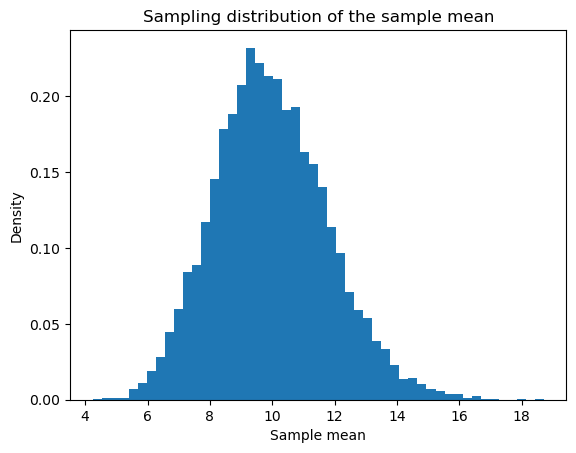

In [11]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# A positively skewed population
population = rng.exponential(scale=10, size=200_000)

# Repeated samples; each row represents one sample
n = 30
num_samples = 10_000

samples = rng.exponential(
    scale=10,
    size=(num_samples, n)
)

sample_means = samples.mean(axis=1)

fig, ax = plt.subplots()
ax.hist(sample_means, bins=50, density=True)
ax.set_title("Sampling distribution of the sample mean")
ax.set_xlabel("Sample mean")
ax.set_ylabel("Density")
plt.show()

In [12]:
import numpy as np
from scipy.stats import norm

# Observed data summary
mu_0 = 60.0
sample_mean = 64.0
sigma = 14.142
n = 25
alpha = 0.05

# Standard error and Z-statistic
se = sigma / np.sqrt(n)
z_stat = (sample_mean - mu_0) / se

# Two-sided p-value
p_value = 2 * norm.sf(abs(z_stat))

# 95% confidence interval
critical_z = norm.ppf(1 - alpha / 2)
margin_of_error = critical_z * se
ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"Standard error: {se:.4f}")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

if p_value <= alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Standard error: 2.8284
Z-statistic: 1.4142
P-value: 0.1573
95% CI: [58.46, 69.54]
Fail to reject the null hypothesis.
